# Module 1 — Causal Diagnosis of Delivery Delay

## Business question
Which factors *cause* delivery delay, not merely correlate with it? Operational decisions
(switching carrier, changing shipping mode, reallocating a distribution center) are only worth
making if the effect is causal, not coincidental.

## Dataset
DataCo Smart Supply Chain for Big Data Analysis — 180,519 orders, 53 columns, 2015–2019.

## 1. Setup & imports

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from causal import (
    estimate_propensity_scores,
    nearest_neighbor_match,
    standardized_mean_difference,
    average_treatment_effect,
)

pd.set_option('display.max_columns', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Load and prepare data

In [2]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin1')
df.columns = [c.strip() for c in df.columns]
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['order_month'] = df['order date (DateOrders)'].dt.month
df['delay_days'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

print(df.shape)
df[['Shipping Mode', 'Days for shipping (real)', 'Days for shipment (scheduled)',
    'delay_days', 'Late_delivery_risk']].head()


(180519, 55)


,Shipping Mode,Days for shipping (real),Days for shipment (scheduled),delay_days,Late_delivery_risk
0,Standard Class,3,4,-1,0
1,Standard Class,5,4,1,1
2,Standard Class,4,4,0,0
3,Standard Class,3,4,-1,0
4,Standard Class,2,4,-2,0


## 3. A critical data-quality check before any causal claim

Before trusting `Late_delivery_risk` as an outcome, check whether the *promised* delivery
window (`Days for shipment (scheduled)`) actually varies within each shipping mode, or whether
it is fixed by design.

In [3]:
schedule_variance = df.groupby('Shipping Mode')['Days for shipment (scheduled)'].agg(['mean', 'std', 'min', 'max'])
schedule_variance


,mean,std,min,max
Shipping Mode,,,,
First Class,1.0,0.0,1,1
Same Day,0.0,0.0,0,0
Second Class,2.0,0.0,2,2
Standard Class,4.0,0.0,4,4


**Finding:** `Days for shipment (scheduled)` has **zero variance** within every shipping
mode — First Class is always promised in 1 day, Same Day in 0 days, Second Class in 2 days,
Standard Class in 4 days. This means the promised window is fixed by shipping-mode label, not
by any operational assessment of the specific order.

As a direct consequence, `Late_delivery_risk` (a flag built from real vs scheduled days) is
mechanically dominated by how tight each mode's own promise is — First Class shows ~95% "late"
risk almost by construction, since its 1-day promise is very hard to beat even when the actual
delivery is fast in absolute terms. Treating this flag as the causal outcome would conflate a
labeling artifact with genuine operational performance.

**Decision:** the causal analysis instead uses `delay_days` (real days − scheduled days) as a
continuous outcome, and restricts the treatment comparison to **Second Class vs Standard
Class** — the only two modes exhibiting genuine order-to-order variation in delivery time,
making a causal comparison meaningful.

In [4]:
delay_variance = df.groupby('Shipping Mode')['delay_days'].agg(['mean', 'std', 'min', 'max'])
delay_variance


,mean,std,min,max
Shipping Mode,,,,
First Class,1.000000,0.000000,1,1
Same Day,0.478279,0.499554,0,1
Second Class,1.990828,1.415900,0,4
Standard Class,-0.004093,1.417266,-2,2


## 4. Naive (unadjusted) comparison — Second Class vs Standard Class

In [5]:
sub = df[df['Shipping Mode'].isin(['Second Class', 'Standard Class'])].copy()
sub['treatment'] = (sub['Shipping Mode'] == 'Second Class').astype(int)

print(f"Sample size: {sub.shape[0]:,} orders "
      f"({sub['treatment'].sum():,} Second Class / {(sub['treatment']==0).sum():,} Standard Class)")

naive_means = sub.groupby('treatment')['delay_days'].mean()
naive_gap = naive_means[1] - naive_means[0]
print(f"\nNaive mean delay_days — Standard Class: {naive_means[0]:.3f} | Second Class: {naive_means[1]:.3f}")
print(f"Naive (unadjusted) gap: {naive_gap:.3f} days")


Sample size: 142,968 orders (35,216 Second Class / 107,752 Standard Class)

Naive mean delay_days — Standard Class: -0.004 | Second Class: 1.991
Naive (unadjusted) gap: 1.995 days


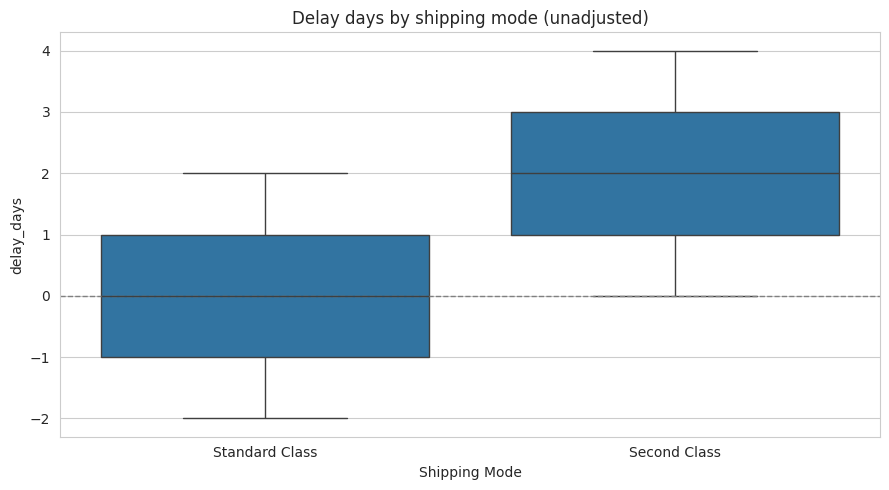

In [6]:
fig, ax = plt.subplots()
sns.boxplot(data=sub, x='Shipping Mode', y='delay_days', ax=ax)
ax.set_title('Delay days by shipping mode (unadjusted)')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.savefig('../reports/figures/module1_naive_delay_boxplot.png', dpi=120)
plt.show()


## 5. Propensity score estimation
Covariates: region, product category, customer segment, order month, order value.

In [7]:
covariates = ['Order Region', 'Category Name', 'Customer Segment', 'order_month', 'Order Item Total']
sub_model = sub.dropna(subset=covariates + ['treatment', 'delay_days']).copy()

ps = estimate_propensity_scores(sub_model, 'treatment', covariates)
sub_model['propensity_score'] = ps

print(f"Model sample: {sub_model.shape[0]:,} orders")
sub_model['propensity_score'].describe()


Model sample: 142,968 orders


count    142968.000000
mean          0.246311
std           0.015203
min           0.118084
25%           0.239046
50%           0.246368
75%           0.254239
max           0.350064
Name: propensity_score, dtype: float64

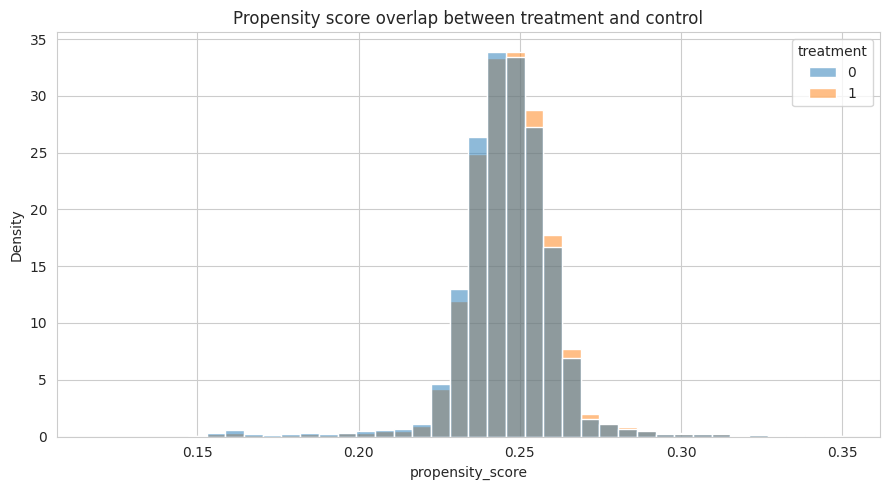

In [8]:
fig, ax = plt.subplots()
sns.histplot(data=sub_model, x='propensity_score', hue='treatment', bins=40,
             stat='density', common_norm=False, alpha=0.5, ax=ax)
ax.set_title('Propensity score overlap between treatment and control')
plt.tight_layout()
plt.savefig('../reports/figures/module1_propensity_overlap.png', dpi=120)
plt.show()


The propensity score range is narrow (roughly 0.12–0.35),
meaning the chosen covariates explain very little of why an order ends up as Second Class vs
Standard Class — most of the assignment looks close to random with respect to region, category,
segment, month, and order value. That context matters for interpreting the matched result
below.

## 6. Nearest-neighbor matching & balance check

In [9]:
matched = nearest_neighbor_match(sub_model, 'treatment', caliper=0.01)
print(f"Matched sample: {matched.shape[0]:,} orders "
      f"({matched['treatment'].sum():,} per group)")

smd_before = standardized_mean_difference(sub_model, 'treatment', 'Order Item Total')
smd_after = standardized_mean_difference(matched, 'treatment', 'Order Item Total')
print(f"\nSMD (Order Item Total) — before matching: {smd_before:.4f} | after matching: {smd_after:.4f}")
print("Balance target: |SMD| < 0.1 -> ", "PASS" if abs(smd_after) < 0.1 else "FAIL")


Matched sample: 70,432 orders (35,216 per group)

SMD (Order Item Total) — before matching: -0.0124 | after matching: -0.0265
Balance target: |SMD| < 0.1 ->  PASS


## 7. Average Treatment Effect (ATE) — unadjusted vs matched

In [10]:
result_unadjusted = average_treatment_effect(sub_model, 'treatment', 'delay_days')
result_matched = average_treatment_effect(matched, 'treatment', 'delay_days')

print("Unadjusted ATE:", {k: round(v, 3) for k, v in result_unadjusted.items()})
print("Matched ATE:   ", {k: round(v, 3) for k, v in result_matched.items()})


Unadjusted ATE: {'ate': np.float64(1.995), 'ci_low': np.float64(1.978), 'ci_high': np.float64(2.011)}
Matched ATE:    {'ate': np.float64(1.99), 'ci_low': np.float64(1.969), 'ci_high': np.float64(2.01)}


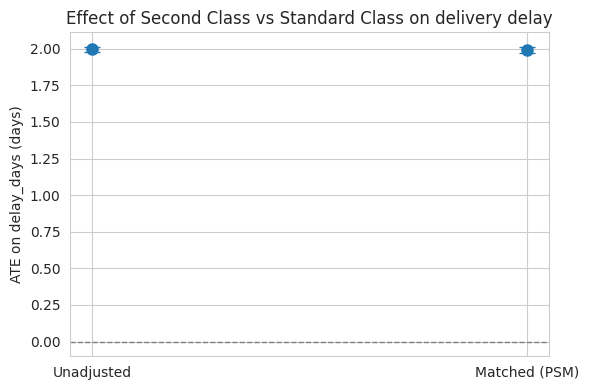

In [11]:
labels = ['Unadjusted', 'Matched (PSM)']
ates = [result_unadjusted['ate'], result_matched['ate']]
ci_low = [result_unadjusted['ci_low'], result_matched['ci_low']]
ci_high = [result_unadjusted['ci_high'], result_matched['ci_high']]
errors = [[a - l for a, l in zip(ates, ci_low)], [h - a for a, h in zip(ates, ci_high)]]

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(labels, ates, yerr=errors, fmt='o', capsize=6, markersize=8)
ax.set_ylabel('ATE on delay_days (days)')
ax.set_title('Effect of Second Class vs Standard Class on delivery delay')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.savefig('../reports/figures/module1_ate_comparison.png', dpi=120)
plt.show()


## 8. Interpreting the treatment effect

The ATE is essentially unchanged after matching (from the unadjusted estimate to the matched
estimate, both landing close to **~2.0 extra days** for Second Class relative to Standard
Class, with tight confidence intervals). Combined with the narrow, overlapping propensity
score range from Step 5, the stability itself is informative: the delay gap between these two
modes is **not explained by region, category, customer segment, order timing, or order
value** — it is a stable, structural property of the shipping mode itself, not a confound of
who orders what, from where.

The claim is stronger and more honest than a naive correlation, precisely because the
adjustment was attempted and did not explain the gap away.

## 9. Financial translation

In [12]:
cost_per_order = sub_model.groupby('treatment')['Order Profit Per Order'].mean()
print("Average profit per order by group:")
print(cost_per_order)

profit_gap = cost_per_order[0] - cost_per_order[1]
print(f"\nStandard Class shows ${profit_gap:.2f} higher average profit per order than Second Class.")
print("This is a descriptive association (not itself causally estimated here) that motivates")
print("a follow-up: pricing/cost data would let this be converted into a defensible dollar ATE.")


Average profit per order by group:
treatment
0    21.999169
1    21.305889
Name: Order Profit Per Order, dtype: float64

Standard Class shows $0.69 higher average profit per order than Second Class.
This is a descriptive association (not itself causally estimated here) that motivates
a follow-up: pricing/cost data would let this be converted into a defensible dollar ATE.


## 10. Conclusions & limitations

**Finding:** Second Class shipping causes approximately 2 additional days of delay relative to
Standard Class, and this effect is robust to adjustment for region, category, customer segment,
order timing, and order value — the covariates tested do not explain the gap.

**Business implication:** if Second Class and Standard Class serve comparable order profiles
(which the balance check supports), shifting volume from Second Class toward Standard Class — or
renegotiating Second Class carrier terms — is a lever with a stable, well-estimated effect size.

**Limitations (must be stated explicitly):**
- This remains an **observational, quasi-causal** estimate. Matching reduces confounding on
  observed covariates only; unobserved confounders (e.g. warehouse-level operational load) could
  still bias the result.
- First Class and Same Day were **excluded** from causal comparison because their scheduled
  window has zero variance, making `delay_days` for those modes a mechanical function of
  shipping-mode label rather than a comparable outcome.
- The financial translation in Step 9 is descriptive, not a causally estimated dollar effect —
  it flags a follow-up question rather than answering it.